# Experiment 2 — Identical means, different shapes: nonparametric separation

> **⚠️ Working structural draft — not final.** Experiment 2's actual instance
> families/grid are still being finalized (trimming `moment_matched_mixture`'s
> grid, and a new geometric family under discussion to possibly join or
> replace `ring_blob`). This notebook is built against the **current**
> `configs/exp2.yaml` families (`scale_pair`, `moment_matched_mixture`,
> `ring_blob`) purely to validate the plotting structure against
> `results/exp2/`'s smoke-test output. Figure content, family choice, and grid
> will change once Experiment 2's design settles — re-run/adjust this notebook
> then, do not treat these figures as paper-ready.

Figures per `docs/experiments.md`, Experiment 2 “Figures” subsection. This
notebook only loads `results/exp2/results.parquet` and plots — it never
recomputes (see CLAUDE.md and `docs/experiments.md` §0.4). Run `make exp2`
(or `make smoke`) first if that file is missing.

**Note:** as of this run, `results/exp2/` holds `SMOKE_TEST` output (reduced
grid, 5 reps, smaller N) — figures below are structurally correct but not the
paper's real grid/rep counts.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from kabc.plotting import set_style, style_for, legend_for_algorithms, savefig, ALGO_ORDER, ALGO_COLORS, ALGO_LABELS
from kabc.environments import RingBlobEnv

set_style()

RESULTS_PATH = Path("../results/exp2/results.parquet")
if not RESULTS_PATH.exists():
    raise FileNotFoundError(
        f"{RESULTS_PATH} not found. Run `make exp2` (or `make smoke`) to generate it — "
        "this notebook only plots existing results, it never recomputes them."
    )
df = pd.read_parquet(RESULTS_PATH)
print(f"loaded {len(df)} rows from {RESULTS_PATH}")
print("families present:", sorted(df['family'].unique()))
df.head()

loaded 125 rows from ../results/exp2/results.parquet
families present: ['moment_matched_mixture', 'ring_blob', 'scale_pair']


,exp_id,family,algorithm,rep,seed,swept_param,swept_value,budget_cap,s_star,tau,...,Delta,sigma,sigma_B,a,ring_radius,ring_noise,data_dir,arms_per_prototype,min_ratings,mean_gap_tol
0,2,scale_pair,kabc,0,2000,sigma_B,1.5,10000,0.252883,4968,...,None,None,1.5,NaN,NaN,NaN,None,None,None,None
1,2,scale_pair,kabc,1,2001,sigma_B,1.5,10000,0.252883,4968,...,None,None,1.5,NaN,NaN,NaN,None,None,None,None
2,2,scale_pair,kabc,2,2002,sigma_B,1.5,10000,0.252883,4968,...,None,None,1.5,NaN,NaN,NaN,None,None,None,None
3,2,scale_pair,kabc,3,2003,sigma_B,1.5,10000,0.252883,4968,...,None,None,1.5,NaN,NaN,NaN,None,None,None,None
4,2,scale_pair,kabc,4,2004,sigma_B,1.5,10000,0.252883,4968,...,None,None,1.5,NaN,NaN,NaN,None,None,None,None


## Figure 1 (headline, family 2b `moment_matched_mixture`)

Left: the two densities at `a = 0.8` (or the closest available grid point in
this smoke-scale run) — same mean/variance, different shape (density curves
computed analytically here, not from a bandit run — this is a description of
the instance, not a result). Right: τ vs MMD² gap (log-log) for
kabc/kabc-sg/kabc-oracle, plus a horizontal band showing ACB's ARI stuck near
0 across all budgets up to cap.

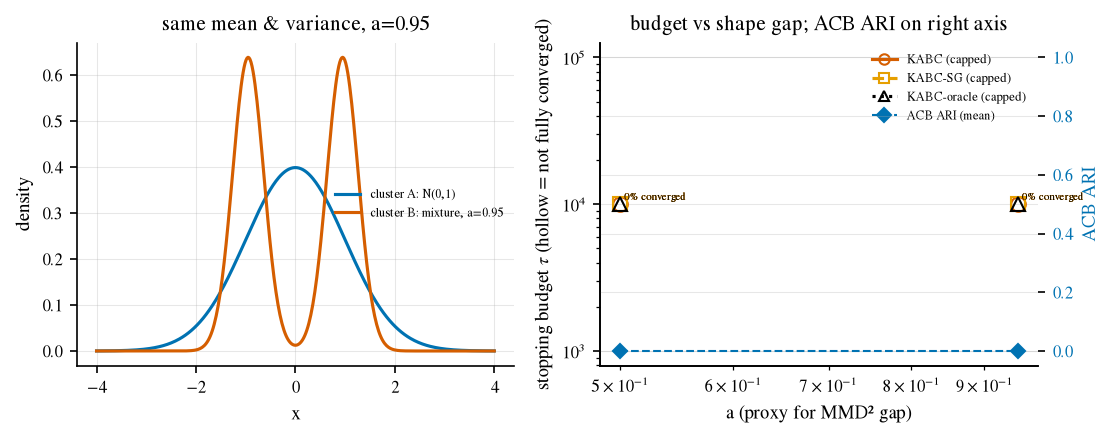

Convergence summary (Fig 1, moment_matched_mixture):
  kabc: 
             mean_tau  frac_stopped  budget_cap
swept_value                                    
0.50              NaN           0.0     10000.0
0.95              NaN           0.0     10000.0

  kabc-sg: 
             mean_tau  frac_stopped  budget_cap
swept_value                                    
0.50              NaN           0.0     10000.0
0.95              NaN           0.0     10000.0

  kabc-oracle: 
             mean_tau  frac_stopped  budget_cap
swept_value                                    
0.50              NaN           0.0     10000.0
0.95              NaN           0.0     10000.0



In [2]:
from scipy.stats import norm

mm_df = df[df["family"] == "moment_matched_mixture"].copy()
target_a = 0.8
a_values = sorted(mm_df["swept_value"].unique())
plot_a = min(a_values, key=lambda a: abs(a - target_a))


def tau_summary(sub_df):
    """Per (algorithm, grid point): mean tau over CONVERGED (stopped==True)
    reps only, plus the fraction of reps that instead hit budget_cap.
    Blending capped reps into the mean would understate the true budget at
    hard grid points -- the wrong direction for a plot whose whole point is
    "how big does tau get". A grid point with zero converged reps has no
    real tau to report; we surface budget_cap as a visually distinct
    reference (hollow marker), never as a stand-in tau value."""
    frac_stopped = sub_df["stopped"].mean()
    stopped_rows = sub_df[sub_df["stopped"]]
    mean_tau = stopped_rows["tau"].mean() if len(stopped_rows) > 0 else np.nan
    return pd.Series({"mean_tau": mean_tau, "frac_stopped": frac_stopped, "budget_cap": sub_df["budget_cap"].iloc[0]})


def plot_tau_with_capping(ax, sub_df, algo, x_col="swept_value"):
    """Plot one algorithm's tau curve, distinguishing converged points
    (filled marker, solid line) from partially/fully-capped points (hollow
    marker, annotated with the capped fraction, not connected by a solid
    line to neighboring converged points)."""
    summ = sub_df[sub_df["algorithm"] == algo].groupby(x_col).apply(tau_summary, include_groups=False).sort_index()
    style = style_for(algo)
    converged = summ[summ["frac_stopped"] == 1.0]
    capped = summ[summ["frac_stopped"] < 1.0]

    if len(converged) > 0:
        ax.plot(converged.index, converged["mean_tau"], linestyle=style["linestyle"],
                 marker=style["marker"], color=style["color"], label=style["label"])
    for x, row in capped.iterrows():
        y = row["mean_tau"] if not np.isnan(row["mean_tau"]) else row["budget_cap"]
        ax.plot(x, y, marker=style["marker"], markerfacecolor="none",
                 markeredgecolor=style["color"], markersize=7, linestyle="none")
        ax.annotate(f"{row['frac_stopped']*100:.0f}% converged", (x, y),
                     fontsize=5, color=style["color"], xytext=(2, 2), textcoords="offset points")
    if len(converged) == 0 and len(capped) > 0 and len(sub_df[sub_df['algorithm'] == algo]) > 0:
        # nothing converged anywhere for this algo -- still register a legend entry
        ax.plot([], [], linestyle=style["linestyle"], marker=style["marker"],
                 markerfacecolor="none", color=style["color"], label=style["label"] + " (capped)")
    return summ


fig, axes = plt.subplots(1, 2, figsize=(7.5, 3))

ax = axes[0]
x = np.linspace(-4, 4, 400)
b = np.sqrt(max(1 - plot_a**2, 1e-6))
density_a = norm.pdf(x, 0, 1)
density_b = 0.5 * norm.pdf(x, -plot_a, b) + 0.5 * norm.pdf(x, plot_a, b)
ax.plot(x, density_a, color="#0072B2", label="cluster A: N(0,1)")
ax.plot(x, density_b, color="#D55E00", label=f"cluster B: mixture, a={plot_a}")
ax.set_xlabel("x")
ax.set_ylabel("density")
ax.set_title(f"same mean & variance, a={plot_a}")
ax.legend(fontsize=6, frameon=False)

ax = axes[1]
mm_tau_summaries = {}
for algo in [a for a in ["kabc", "kabc-sg", "kabc-oracle"] if a in mm_df["algorithm"].unique()]:
    mm_tau_summaries[algo] = plot_tau_with_capping(ax, mm_df, algo)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("a (proxy for MMD² gap)")
ax.set_ylabel(r"stopping budget $\tau$ (hollow = not fully converged)")
ax.set_title("budget vs shape gap; ACB ARI on right axis")

if "acb" in mm_df["algorithm"].unique():
    # ACB's ARI lives on [0,1], budget tau lives on a log scale spanning
    # orders of magnitude -- an earlier version plotted ACB's ARI band via
    # axhspan directly on the tau axis (mislabeled "(right axis)" without
    # ever creating one), which either rendered invisibly (ARI values near
    # 0 vanish against a 10^3-10^5 y-range) or was meaningless regardless of
    # value. A genuine twin axis fixes both: correct scale, and a real
    # visible marker/line even when ACB's ARI is flat (e.g. exactly 0 at
    # every grid point, the expected "mean-blind" result for this family).
    acb_by_a = mm_df[mm_df["algorithm"] == "acb"].groupby("swept_value")["ari"].agg(["mean", "min", "max"]).sort_index()
    ax2 = ax.twinx()
    ax2.plot(acb_by_a.index, acb_by_a["mean"], color=ALGO_COLORS["acb"], marker="D",
              markersize=5, linestyle="--", linewidth=1, label="ACB ARI (mean)")
    if (acb_by_a["max"] - acb_by_a["min"]).max() > 1e-9:
        ax2.fill_between(acb_by_a.index, acb_by_a["min"], acb_by_a["max"], color=ALGO_COLORS["acb"], alpha=0.15)
    ax2.set_ylim(-0.05, 1.05)
    ax2.set_ylabel("ACB ARI", color=ALGO_COLORS["acb"])
    ax2.tick_params(axis="y", labelcolor=ALGO_COLORS["acb"])
    lines1, labels1 = ax.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax.legend(lines1 + lines2, labels1 + labels2, fontsize=6, frameon=False, loc="upper right")
else:
    ax.legend(fontsize=6, frameon=False)

fig.tight_layout()
savefig(fig, "exp2_fig1_moment_matched_headline", fig_dir="../results/figures")
plt.show()

print("Convergence summary (Fig 1, moment_matched_mixture):")
for algo, summ in mm_tau_summaries.items():
    print(f"  {algo}: \n{summ}\n")

## Figure 2 (family 2a `scale_pair`): τ vs sigma_B, with ACB ARI-vs-budget inset

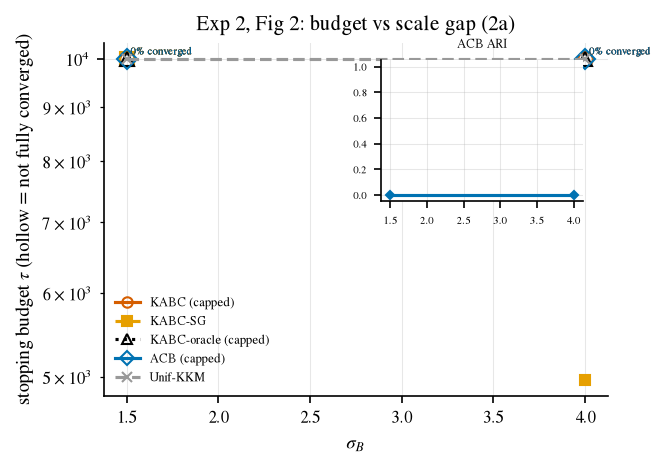

Convergence summary (Fig 2, scale_pair):
  kabc: 
             mean_tau  frac_stopped  budget_cap
swept_value                                    
1.5               NaN           0.0     10000.0
4.0               NaN           0.0     10000.0

  kabc-sg: 
             mean_tau  frac_stopped  budget_cap
swept_value                                    
1.5               NaN           0.0     10000.0
4.0            4968.0           1.0     10000.0

  kabc-oracle: 
             mean_tau  frac_stopped  budget_cap
swept_value                                    
1.5               NaN           0.0     10000.0
4.0               NaN           0.0     10000.0

  acb: 
             mean_tau  frac_stopped  budget_cap
swept_value                                    
1.5               NaN           0.0     10000.0
4.0               NaN           0.0     10000.0



In [3]:
sp_df = df[df["family"] == "scale_pair"].copy()

fig, ax = plt.subplots(figsize=(4.5, 3.2))
sp_tau_summaries = {}
for algo in [a for a in ALGO_ORDER if a in sp_df["algorithm"].unique() and a != "unif-kkm"]:
    sp_tau_summaries[algo] = plot_tau_with_capping(ax, sp_df, algo)
# unif-kkm is non-adaptive (sweeps n, always "converges" by construction) --
# plot it plainly, capping logic doesn't apply.
if "unif-kkm" in sp_df["algorithm"].unique():
    g = sp_df[sp_df["algorithm"] == "unif-kkm"].groupby("swept_value")["tau"].mean().sort_index()
    ax.plot(g.index, g.values, **style_for("unif-kkm"))
ax.set_xlabel(r"$\sigma_B$")
ax.set_ylabel(r"stopping budget $\tau$ (hollow = not fully converged)")
ax.set_yscale("log")
ax.set_title("Exp 2, Fig 2: budget vs scale gap (2a)")
ax.legend(fontsize=6, frameon=False)

if "acb" in sp_df["algorithm"].unique():
    inset = ax.inset_axes([0.55, 0.55, 0.4, 0.4])
    acb_ari_by_sigma = sp_df[sp_df["algorithm"] == "acb"].groupby("swept_value")["ari"].mean().sort_index()
    inset.plot(acb_ari_by_sigma.index, acb_ari_by_sigma.values, color=ALGO_COLORS["acb"], marker="D", markersize=3)
    inset.set_ylim(-0.05, 1.05)
    inset.set_title("ACB ARI", fontsize=6)
    inset.tick_params(labelsize=5)

fig.tight_layout()
savefig(fig, "exp2_fig2_scale_pair", fig_dir="../results/figures")
plt.show()

print("Convergence summary (Fig 2, scale_pair):")
for algo, summ in sp_tau_summaries.items():
    print(f"  {algo}: \n{summ}\n")

## Figure 3: price of adaptivity — τ(kabc)/τ(kabc-oracle) across all Exp-2 configs

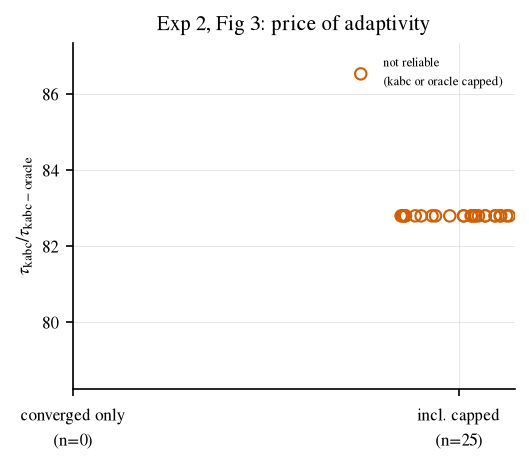

0/25 grid-point reps have BOTH kabc and kabc-oracle converged (reliable ratio); 25 rep(s) had at least one side capped and are shown separately, not folded into the summary statistic.
No reliable price-of-adaptivity estimate available from the current (smoke-test) results -- re-run with a real, uncapped grid to populate this figure.


In [4]:
key_cols = ["family", "swept_param", "swept_value", "rep", "seed"]
kabc_rows = df[df["algorithm"] == "kabc"].set_index(key_cols)
oracle_rows = df[df["algorithm"] == "kabc-oracle"].set_index(key_cols)

joined = kabc_rows[["tau", "stopped", "budget_cap"]].join(
    oracle_rows[["tau", "stopped"]], lsuffix="_kabc", rsuffix="_oracle", how="inner"
)
joined["both_converged"] = joined["stopped_kabc"] & joined["stopped_oracle"]
joined["ratio"] = joined["tau_kabc"] / joined["tau_oracle"]

reliable = joined[joined["both_converged"]]
unreliable = joined[~joined["both_converged"]]

fig, ax = plt.subplots(figsize=(3.6, 3.2))
if len(reliable) > 0:
    ax.boxplot(reliable["ratio"].values, positions=[0], widths=0.5, patch_artist=True,
               boxprops=dict(facecolor=ALGO_COLORS["kabc"], alpha=0.6), showfliers=True)

if len(unreliable) > 0:
    # ratios computed from at least one capped run: plotted as hollow,
    # jittered points, clearly separated from the "reliable" box -- a
    # capped/capped ratio is not a real price of adaptivity, just
    # budget_cap / n_oracle, and must never be mistaken for one.
    jitter = np.random.default_rng(0).uniform(-0.15, 0.15, size=len(unreliable))
    ax.scatter(1 + jitter, unreliable["ratio"].values, facecolors="none",
               edgecolors=ALGO_COLORS["kabc"], s=30, label="not reliable\n(kabc or oracle capped)")
    ax.legend(fontsize=6, frameon=False, loc="upper right")

if len(reliable) == 0 and len(unreliable) == 0:
    ax.text(0.5, 0.5, "no kabc/kabc-oracle rows found", ha="center", va="center",
             fontsize=7, transform=ax.transAxes)

ax.set_xticks([0, 1])
ax.set_xticklabels([f"converged only\n(n={len(reliable)})", f"incl. capped\n(n={len(unreliable)})"])
ax.set_ylabel(r"$\tau_{\mathrm{kabc}} / \tau_{\mathrm{kabc-oracle}}$")
ax.set_title("Exp 2, Fig 3: price of adaptivity")
fig.tight_layout()
savefig(fig, "exp2_fig3_price_of_adaptivity", fig_dir="../results/figures")
plt.show()

n_total = len(joined)
n_reliable = len(reliable)
print(f"{n_reliable}/{n_total} grid-point reps have BOTH kabc and kabc-oracle converged "
      f"(reliable ratio); {n_total - n_reliable} rep(s) had at least one side capped "
      f"and are shown separately, not folded into the summary statistic.")
if n_reliable > 0:
    print(reliable["ratio"].describe())
else:
    print("No reliable price-of-adaptivity estimate available from the current "
          "(smoke-test) results -- re-run with a real, uncapped grid to populate this figure.")

## Figure 4 (family 2c `ring_blob`): scatter of dataset + recovered partition

The ring/blob dataset itself is reconstructed deterministically from
`RingBlobEnv` (same `base` kwargs as `configs/exp2.yaml`'s `ring_blob`
family) purely to plot the raw points — not a re-run of any algorithm. The
recovered partition is taken from a stored result row's `partition` column.

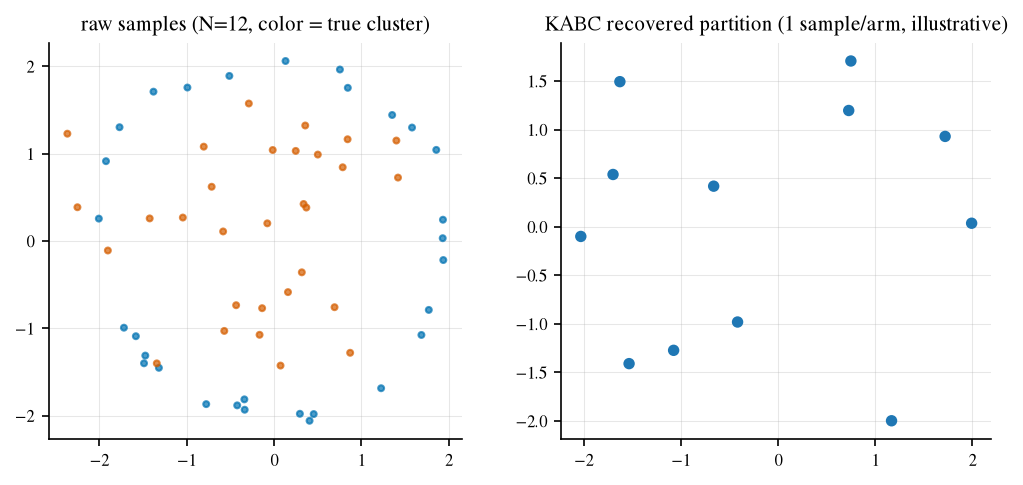

In [5]:
rb_df = df[df["family"] == "ring_blob"].copy()

fig, axes = plt.subplots(1, 2, figsize=(7, 3.2))

# Size the illustrative env to match the N actually used by the loaded
# results (smoke-scale N here, not the paper's N=40) so left/right panels
# and the recovered partition are all consistent with each other.
partition = None
if "kabc" in rb_df["algorithm"].unique() and len(rb_df) > 0:
    partition = np.asarray(rb_df[rb_df["algorithm"] == "kabc"].iloc[0]["partition"])
    env_N = len(partition)
else:
    env_N = 40

rng = np.random.default_rng(0)
env = RingBlobEnv(N=env_N, ring_radius=2.0, ring_noise=0.1)
n_per_arm = 5
points = np.array([env.pull(i, rng) for i in range(env.n_arms) for _ in range(n_per_arm)])
colors = np.repeat(env.true_partition, n_per_arm)
colors = ["#0072B2" if c == 0 else "#D55E00" for c in colors]
axes[0].scatter(points[:, 0], points[:, 1], c=colors, s=8, alpha=0.7)
axes[0].set_title(f"raw samples (N={env_N}, color = true cluster)")
axes[0].set_aspect("equal")

if partition is not None:
    arm_means = np.array([env.pull(i, np.random.default_rng(1000 + i)) for i in range(env.n_arms)])
    cmap = plt.get_cmap("tab10")
    axes[1].scatter(arm_means[:, 0], arm_means[:, 1], c=[cmap(int(p) % 10) for p in partition], s=20)
    axes[1].set_title("KABC recovered partition (1 sample/arm, illustrative)")
else:
    axes[1].text(0.5, 0.5, "no kabc result available for ring_blob", ha="center", va="center")
axes[1].set_aspect("equal")

fig.tight_layout()
savefig(fig, "exp2_fig4_ring_blob", fig_dir="../results/figures")
plt.show()